# Gaussian process regression for IDH status

This notebook compares patient-level Gaussian process regression (GPR) approaches for separating IDH-mutant from IDH-wildtype glioma samples. It follows the class mapping and patient-stratified folds from `01_data_exploration.ipynb`. The full process, interpretation, limitations, and next steps are in [`03_gaussian_process_regression_test.md`](03_gaussian_process_regression_test.md).

The independent observation is a patient. Every patient's spectra are reduced to one mean spectrum, and all transforms and outlier decisions are fit inside each training fold. The fixed five-fold results are exploratory because the same folds are used to compare the candidate methods.

In [13]:
from collections import Counter
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2, norm
from sklearn.covariance import MinCovDet
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    RationalQuadratic,
    RBF,
    WhiteKernel,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_CANDIDATES = [Path("../data/preprocessed.npy"), Path("data/preprocessed.npy")]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find data/preprocessed.npy relative to the notebook or repository root.")

dataset = np.load(DATA_PATH, allow_pickle=True)
entry_records = pd.DataFrame([
    {
        "entry_index": index,
        "patient_id": int(item["patient_id"]),
        "class_id": int(item["class_id"]),
        "target": int(item["class_id"] >= 4),  # 0 = mutant, 1 = wildtype
    }
    for index, item in enumerate(dataset)
])

# Match notebook 01: one patient row, with patient IDs sorted by groupby.
patient_ids = []
patient_targets = []
patient_mean_spectra = []
channel_count = int(dataset[0]["data"].shape[-1])
for patient_id, entries in entry_records.groupby("patient_id", sort=True):
    targets = entries["target"].unique()
    if len(targets) != 1:
        raise ValueError(f"Patient {patient_id} has more than one binary target.")

    intensity_sum = np.zeros(channel_count, dtype=np.float64)
    spectrum_count = 0
    for entry_index in entries["entry_index"].to_numpy(dtype=int):
        spectra = np.asarray(dataset[entry_index]["data"]).reshape(-1, channel_count)
        intensity_sum += spectra.sum(axis=0)
        spectrum_count += len(spectra)

    patient_ids.append(int(patient_id))
    patient_targets.append(int(targets[0]))
    patient_mean_spectra.append(intensity_sum / spectrum_count)

patient_ids = np.asarray(patient_ids)
y = np.asarray(patient_targets, dtype=int)
X = np.vstack(patient_mean_spectra)
patient_table = pd.DataFrame({"patient_id": patient_ids, "target": y})

print(f"Sample entries: {len(entry_records)}")
print(f"Patients: {len(patient_table)}; spectra channels: {X.shape[1]}")
print("Patient counts (0 = IDH-mutant, 1 = IDH-wildtype):", dict(Counter(y)))


Sample entries: 59
Patients: 46; spectra channels: 1167
Patient counts (0 = IDH-mutant, 1 = IDH-wildtype): {np.int64(0): 21, np.int64(1): 25}


## Reconstruct the patient-level folds

Notebook 01 assigns validation patients with `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` after grouping patients in sorted ID order. Reconstructing the same assignment here keeps the validation base comparable.

In [14]:
N_SPLITS = 5
RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

patient_table["fold"] = -1
for fold, (_, validation_positions) in enumerate(cv.split(patient_ids, y)):
    patient_table.loc[validation_positions, "fold"] = fold

fold_summary = (
    patient_table.groupby("fold")
    .agg(
        validation_patients=("patient_id", "size"),
        IDHmutant_patients=("target", lambda values: int((values == 0).sum())),
        IDHwildtype_patients=("target", lambda values: int((values == 1).sum())),
    )
)
fold_summary.index = fold_summary.index + 1
fold_summary.index.name = "fold"
print(fold_summary.to_string())


      validation_patients  IDHmutant_patients  IDHwildtype_patients
fold                                                               
1                      10                   5                     5
2                       9                   4                     5
3                       9                   4                     5
4                       9                   4                     5
5                       9                   4                     5


## Models and out-of-fold evaluation

The regression target is 0 for mutant and 1 for wildtype; the fixed decision threshold is 0.5. PCA, optional channel standardization, and the GP are fitted within the training patients for each fold. The GP kernel is signal variance times the selected covariance kernel plus a white-noise term. RBF and Matérn can use one learned length scale per PCA component (ARD) or a shared length scale (isotropic). The optimizer gets one restart.

The class-conditional outlier check is also training-only. It fits a robust covariance estimate to each class's first two training-fold PCA scores and screens points at a chi-square tail cutoff of 0.01. A second sensitivity fit removes patient 1887 only from training folds where that patient is present. All validation patients remain scored.

In [15]:
model_specs = [
    {"name": "PCA 2 + RBF ARD", "n_components": 2, "kernel": "rbf", "ard": True},
    {"name": "PCA 5 + RBF ARD", "n_components": 5, "kernel": "rbf", "ard": True},
    {"name": "PCA 6 + RBF ARD", "n_components": 6, "kernel": "rbf", "ard": True},
    {"name": "PCA 8 + RBF ARD", "n_components": 8, "kernel": "rbf", "ard": True},
    {"name": "PCA 10 + RBF ARD", "n_components": 10, "kernel": "rbf", "ard": True},
    {"name": "PCA 12 + RBF ARD", "n_components": 12, "kernel": "rbf", "ard": True},
    {"name": "PCA 15 + RBF ARD", "n_components": 15, "kernel": "rbf", "ard": True},
    {"name": "PCA 20 + RBF ARD", "n_components": 20, "kernel": "rbf", "ard": True},
    {"name": "PCA 25 + RBF ARD", "n_components": 25, "kernel": "rbf", "ard": True},
    {"name": "PCA 10 + RBF isotropic", "n_components": 10, "kernel": "rbf", "ard": False},
    {"name": "PCA 10 + Matérn 1.5 ARD", "n_components": 10, "kernel": "matern15", "ard": True},
    {"name": "PCA 10 + Rational Quadratic isotropic", "n_components": 10, "kernel": "rq", "ard": False},
    {"name": "Channel-scaled PCA 10 + RBF ARD", "n_components": 10, "kernel": "rbf", "ard": True, "channel_scale": True},
    {"name": "MCD removal + PCA 10 + RBF ARD", "n_components": 10, "kernel": "rbf", "ard": True, "outlier_method": "classwise_mcd"},
    {"name": "Remove patient 1887 from training + PCA 10 + RBF ARD", "n_components": 10, "kernel": "rbf", "ard": True, "outlier_method": "patient_1887"},
]


def make_covariance_kernel(spec, n_components):
    if spec["kernel"] == "rbf":
        length_scale = np.ones(n_components) if spec["ard"] else 1.0
        component_kernel = RBF(length_scale=length_scale)
    elif spec["kernel"] == "matern15":
        component_kernel = Matern(length_scale=np.ones(n_components), nu=1.5)
    elif spec["kernel"] == "rq":
        component_kernel = RationalQuadratic(length_scale=1.0, alpha=1.0)
    else:
        raise ValueError(f"Unknown kernel: {spec['kernel']}")

    return (
        ConstantKernel(1.0, (1e-3, 1e3)) * component_kernel
        + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e2))
    )


def evaluate_model(spec):
    out_of_fold_scores = np.zeros(len(y), dtype=float)
    out_of_fold_std = np.zeros(len(y), dtype=float)
    fold_accuracies = []
    bound_folds = 0
    convergence_warning_folds = 0
    removed_training_ids = []

    # Reusing this splitter produces exactly one validation prediction per patient.
    for fold, (train_indices, validation_indices) in enumerate(cv.split(X, y)):
        X_train = X[train_indices]
        X_validation = X[validation_indices]
        y_train = y[train_indices].copy()

        if spec.get("channel_scale", False):
            channel_scaler = StandardScaler()
            X_train = channel_scaler.fit_transform(X_train)
            X_validation = channel_scaler.transform(X_validation)

        pca = PCA(n_components=spec["n_components"], random_state=RANDOM_STATE)
        Z_train = pca.fit_transform(X_train)
        Z_validation = pca.transform(X_validation)

        outlier_method = spec.get("outlier_method")
        keep = np.ones(len(train_indices), dtype=bool)
        if outlier_method == "classwise_mcd":
            for class_value in np.unique(y_train):
                class_positions = np.flatnonzero(y_train == class_value)
                robust_covariance = MinCovDet(random_state=RANDOM_STATE).fit(
                    Z_train[class_positions, :2]
                )
                distances = robust_covariance.mahalanobis(Z_train[class_positions, :2])
                tail_probabilities = chi2.sf(distances, df=2)
                keep[class_positions[tail_probabilities < 0.01]] = False
        elif outlier_method == "patient_1887":
            keep = patient_ids[train_indices] != 1887

        removed_training_ids.extend(patient_ids[train_indices[~keep]].tolist())
        Z_train = Z_train[keep]
        y_train = y_train[keep]

        gp = GaussianProcessRegressor(
            kernel=make_covariance_kernel(spec, spec["n_components"]),
            alpha=1e-6,
            normalize_y=True,
            n_restarts_optimizer=1,
            random_state=RANDOM_STATE,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            gp.fit(Z_train, y_train)
        if any(issubclass(item.category, ConvergenceWarning) for item in caught):
            convergence_warning_folds += 1

        validation_mean, validation_std = gp.predict(Z_validation, return_std=True)
        out_of_fold_scores[validation_indices] = validation_mean
        out_of_fold_std[validation_indices] = validation_std
        fold_accuracies.append(
            accuracy_score(y[validation_indices], out_of_fold_scores[validation_indices] >= 0.5)
        )

        theta = gp.kernel_.theta
        bounds = gp.kernel_.bounds
        if np.any(np.isclose(theta, bounds[:, 0], atol=0.05, rtol=0.0)) or np.any(
            np.isclose(theta, bounds[:, 1], atol=0.05, rtol=0.0)
        ):
            bound_folds += 1

    # This is P(regression output > 0.5) under the GP Gaussian predictive distribution,
    # not a calibrated posterior probability for the binary class.
    out_of_fold_prob_wildtype = norm.sf(
        (0.5 - out_of_fold_scores) / np.maximum(out_of_fold_std, 1e-12)
    )
    predicted_labels = (out_of_fold_scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted_labels, labels=[0, 1]).ravel()
    return {
        "name": spec["name"],
        "scores": out_of_fold_scores,
        "stds": out_of_fold_std,
        "prob_wildtype": out_of_fold_prob_wildtype,
        "accuracy": accuracy_score(y, predicted_labels),
        "balanced_accuracy": balanced_accuracy_score(y, predicted_labels),
        "roc_auc": roc_auc_score(y, out_of_fold_scores),
        "confusion_matrix": f"[[{tn}, {fp}], [{fn}, {tp}]]",
        "fold_accuracies": ", ".join(f"{value:.2f}" for value in fold_accuracies),
        "kernel_bound_folds": bound_folds,
        "convergence_warning_folds": convergence_warning_folds,
        "removed_training_appearances": len(removed_training_ids),
        "removed_unique_patients": len(set(removed_training_ids)),
        "removed_patient_ids": removed_training_ids,
    }


model_runs = [evaluate_model(spec) for spec in model_specs]
oof_scores = {run["name"]: run["scores"] for run in model_runs}
oof_stds = {run["name"]: run["stds"] for run in model_runs}
oof_probabilities = {run["name"]: run["prob_wildtype"] for run in model_runs}
model_results = pd.DataFrame([
    {key: value for key, value in run.items() if key not in {"scores", "stds", "prob_wildtype", "removed_patient_ids"}}
    for run in model_runs
])

result_columns = [
    "name", "accuracy", "balanced_accuracy", "roc_auc", "confusion_matrix",
    "fold_accuracies", "kernel_bound_folds", "convergence_warning_folds",
    "removed_training_appearances", "removed_unique_patients",
]
print(model_results[result_columns].to_string(index=False, float_format=lambda value: f"{value:.3f}"))


                                                name  accuracy  balanced_accuracy  roc_auc    confusion_matrix              fold_accuracies  kernel_bound_folds  convergence_warning_folds  removed_training_appearances  removed_unique_patients
                                     PCA 2 + RBF ARD     0.522              0.488    0.434  [[2, 19], [3, 22]] 0.50, 0.56, 0.67, 0.56, 0.33                   4                          4                             0                        0
                                     PCA 5 + RBF ARD     0.630              0.614    0.657  [[9, 12], [5, 20]] 0.70, 0.78, 0.33, 0.67, 0.67                   3                          3                             0                        0
                                     PCA 6 + RBF ARD     0.739              0.730    0.867  [[13, 8], [4, 21]] 0.70, 0.78, 0.67, 0.89, 0.67                   1                          1                             0                        0
                                

## Reading the results

Accuracy uses the 0.5 cutoff, balanced accuracy gives each class equal weight, and ROC AUC measures ranking from the raw GP scores. The probability view uses P(IDH-wildtype) = P(GP regression output > 0.5) under the GP Gaussian predictive distribution, with P(IDH-mutant) as its complement. These are regression-derived threshold-exceedance probabilities, not calibrated posterior class probabilities. The confusion matrix rows are true mutant then true wildtype, with columns predicted mutant then predicted wildtype.

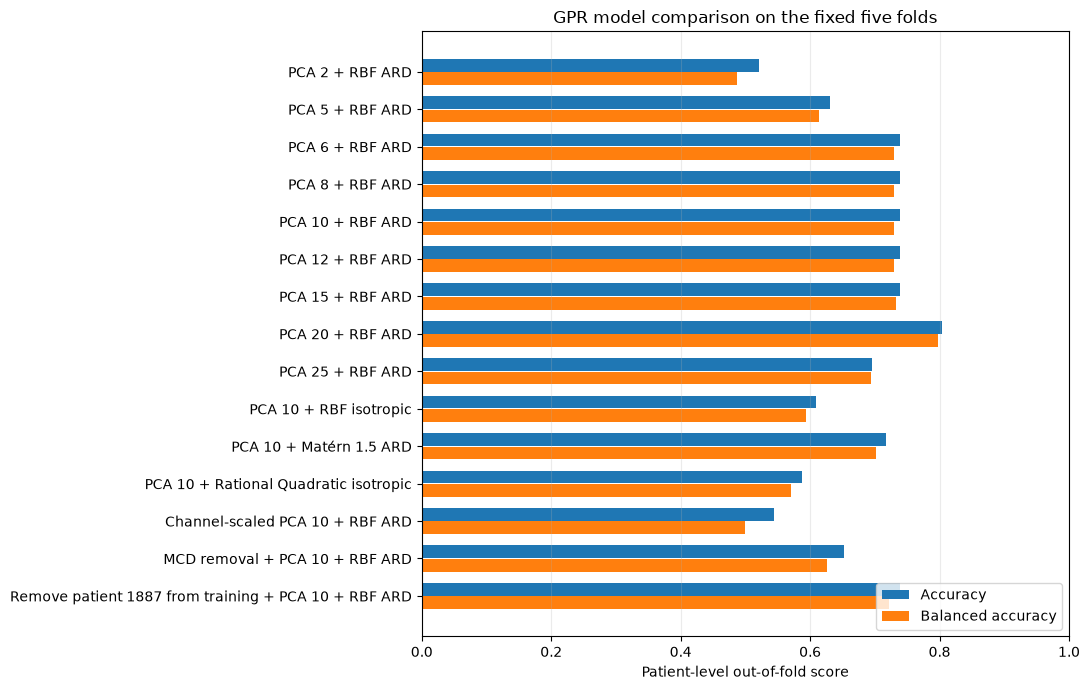

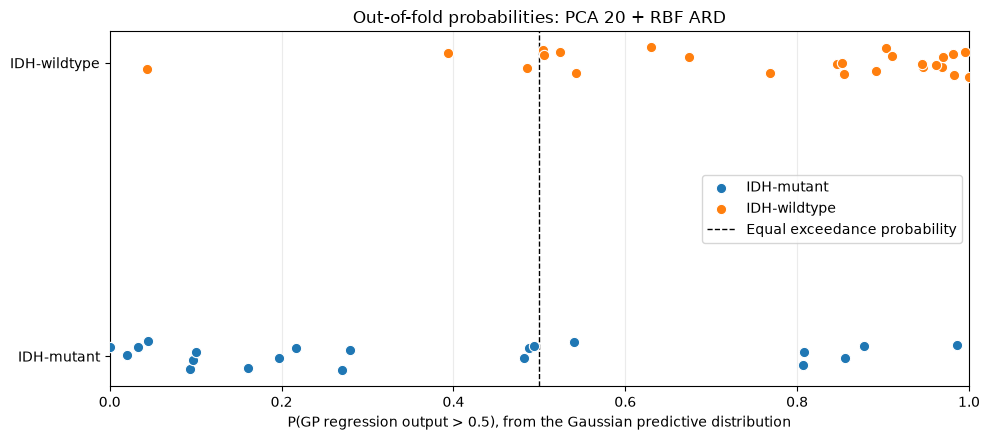

Probability table for the highest-accuracy model: PCA 20 + RBF ARD
 patient_id  fold observed_status  regression_mean  predictive_sd  P_IDHmutant  P_IDHwildtype
        305     1      IDH-mutant           -0.025          0.088        1.000          0.000
        442     4    IDH-wildtype            1.144          0.346        0.031          0.969
        448     5      IDH-mutant            0.246          0.298        0.803          0.197
        592     5    IDH-wildtype            0.593          0.281        0.370          0.630
        615     4      IDH-mutant            1.267          0.350        0.014          0.986
        682     2    IDH-wildtype            0.503          0.286        0.495          0.505
        868     1      IDH-mutant            0.213          0.492        0.720          0.280
        894     5    IDH-wildtype            1.074          0.276        0.019          0.981
        901     2      IDH-mutant            0.064          0.331        0.906         

In [16]:
best_accuracy_name = model_results.loc[model_results["accuracy"].idxmax(), "name"]
best_accuracy_prob_wildtype = oof_probabilities[best_accuracy_name]

fig, ax = plt.subplots(figsize=(11, 7))
positions = np.arange(len(model_results))
ax.barh(positions - 0.18, model_results["accuracy"], height=0.34, label="Accuracy")
ax.barh(positions + 0.18, model_results["balanced_accuracy"], height=0.34, label="Balanced accuracy")
ax.set_yticks(positions, model_results["name"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Patient-level out-of-fold score")
ax.set_title("GPR model comparison on the fixed five folds")
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
rng = np.random.default_rng(RANDOM_STATE)
for class_value, label, color in [(0, "IDH-mutant", "tab:blue"), (1, "IDH-wildtype", "tab:orange")]:
    class_mask = y == class_value
    jitter = rng.uniform(-0.055, 0.055, class_mask.sum())
    ax.scatter(
        best_accuracy_prob_wildtype[class_mask],
        y[class_mask] + jitter,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        s=55,
        label=label,
        zorder=3,
    )
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Equal exceedance probability")
ax.set_xlim(0, 1)
ax.set_yticks([0, 1], ["IDH-mutant", "IDH-wildtype"])
ax.set_xlabel("P(GP regression output > 0.5), from the Gaussian predictive distribution")
ax.set_title(f"Out-of-fold probabilities: {best_accuracy_name}")
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
plt.show()

best_accuracy_scores = oof_scores[best_accuracy_name]
best_accuracy_stds = oof_stds[best_accuracy_name]
probability_table = pd.DataFrame({
    "patient_id": patient_ids,
    "fold": patient_table["fold"].to_numpy() + 1,
    "observed_status": np.where(y == 0, "IDH-mutant", "IDH-wildtype"),
    "regression_mean": best_accuracy_scores,
    "predictive_sd": best_accuracy_stds,
    "P_IDHmutant": 1.0 - best_accuracy_prob_wildtype,
    "P_IDHwildtype": best_accuracy_prob_wildtype,
}).sort_values("patient_id")
print(f"Probability table for the highest-accuracy model: {best_accuracy_name}")
print(probability_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


## Example prediction for one patient

The following example selects a patient by ID and uses the PCA 20 + RBF ARD model. The patient's original validation fold is held out, and the GP is refit only on that fold's training patients. The plots show the selected patient’s predictive density split at the 0.5 regression boundary, threshold-exceedance probabilities for that fold, and probabilities along a one-dimensional interpolation in the 20-dimensional PCA feature space from the nearest training patient to the selected patient. This local slice is not a measured spectrum or a wavelength axis. The Gaussian tail areas are approximate regression-derived probabilities, not calibrated class probabilities.

Patient 1887; validation fold 1
Observed status: IDH-mutant
GP regression score: 0.556; predictive SD: 0.553
Approximate 95% predictive interval: [-0.528, 1.639]
P(IDH-mutant) = P(regression output < 0.5): 0.460
P(IDH-wildtype) = P(regression output > 0.5): 0.540
Mean matches saved out-of-fold run: True


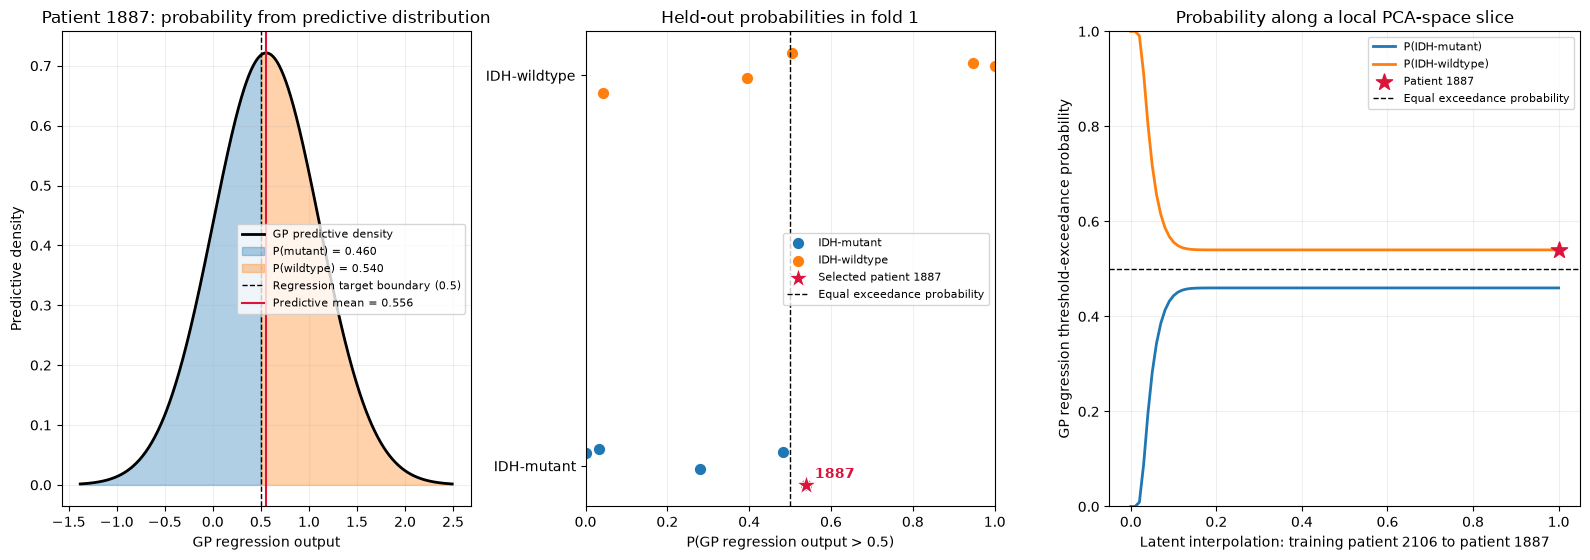

In [17]:
EXAMPLE_PATIENT_ID = 1887  # Change this to another patient ID in patient_table.
EXAMPLE_MODEL_NAME = "PCA 20 + RBF ARD"

query_matches = np.flatnonzero(patient_ids == EXAMPLE_PATIENT_ID)
if len(query_matches) != 1:
    raise ValueError(f"Expected one row for patient {EXAMPLE_PATIENT_ID}; found {len(query_matches)}.")
query_index = int(query_matches[0])
example_fold = int(patient_table.loc[query_index, "fold"])
validation_mask = patient_table["fold"].to_numpy() == example_fold
example_train_indices = np.flatnonzero(~validation_mask)
example_validation_indices = np.flatnonzero(validation_mask)
query_position_in_validation = int(np.flatnonzero(example_validation_indices == query_index)[0])

example_spec = next(spec for spec in model_specs if spec["name"] == EXAMPLE_MODEL_NAME)
example_pca = PCA(n_components=example_spec["n_components"], random_state=RANDOM_STATE)
example_Z_train = example_pca.fit_transform(X[example_train_indices])
example_Z_validation = example_pca.transform(X[example_validation_indices])
example_gp = GaussianProcessRegressor(
    kernel=make_covariance_kernel(example_spec, example_spec["n_components"]),
    alpha=1e-6,
    normalize_y=True,
    n_restarts_optimizer=1,
    random_state=RANDOM_STATE,
)
example_gp.fit(example_Z_train, y[example_train_indices])
fold_scores, fold_std = example_gp.predict(example_Z_validation, return_std=True)
fold_prob_wildtype = norm.sf((0.5 - fold_scores) / np.maximum(fold_std, 1e-12))
query_score = float(fold_scores[query_position_in_validation])
query_std = float(fold_std[query_position_in_validation])
query_interval = (query_score - 1.96 * query_std, query_score + 1.96 * query_std)
query_prob_wildtype = float(fold_prob_wildtype[query_position_in_validation])
query_prob_mutant = 1.0 - query_prob_wildtype
query_target = int(y[query_index])

print(f"Patient {EXAMPLE_PATIENT_ID}; validation fold {example_fold + 1}")
print(f"Observed status: {'IDH-mutant' if query_target == 0 else 'IDH-wildtype'}")
print(f"GP regression score: {query_score:.3f}; predictive SD: {query_std:.3f}")
print(f"Approximate 95% predictive interval: [{query_interval[0]:.3f}, {query_interval[1]:.3f}]")
print(f"P(IDH-mutant) = P(regression output < 0.5): {query_prob_mutant:.3f}")
print(f"P(IDH-wildtype) = P(regression output > 0.5): {query_prob_wildtype:.3f}")
print(f"Mean matches saved out-of-fold run: {np.isclose(query_score, oof_scores[EXAMPLE_MODEL_NAME][query_index])}")

# Find the closest training patient under the learned ARD length-scale metric.
learned_length_scales = np.asarray(example_gp.kernel_.k1.k2.length_scale)
if learned_length_scales.ndim == 0:
    learned_length_scales = np.repeat(learned_length_scales, example_Z_train.shape[1])
query_latent = example_Z_validation[query_position_in_validation]
scaled_distances = np.linalg.norm((example_Z_train - query_latent) / learned_length_scales, axis=1)
nearest_train_position = int(np.argmin(scaled_distances))
nearest_train_patient_id = int(patient_ids[example_train_indices[nearest_train_position]])
nearest_train_latent = example_Z_train[nearest_train_position]

# Interpolate between the nearest training point and the query in the fitted PCA space.
path_fraction = np.linspace(0.0, 1.0, 101)
path_points = nearest_train_latent[None, :] + path_fraction[:, None] * (query_latent - nearest_train_latent)[None, :]
path_mean, path_std = example_gp.predict(path_points, return_std=True)
path_prob_wildtype = norm.sf((0.5 - path_mean) / np.maximum(path_std, 1e-12))
path_prob_mutant = 1.0 - path_prob_wildtype

fig, (ax_density, ax_fold, ax_path) = plt.subplots(1, 3, figsize=(16, 5.7), gridspec_kw={"width_ratios": [1.0, 1.0, 1.15]})

# Show the probability as the area of the patient's Gaussian predictive distribution on either side of 0.5.
density_x = np.linspace(query_score - 3.5 * query_std, query_score + 3.5 * query_std, 500)
density_y = norm.pdf(density_x, loc=query_score, scale=query_std)
ax_density.plot(density_x, density_y, color="black", linewidth=2, label="GP predictive density")
ax_density.fill_between(density_x, density_y, where=density_x < 0.5, color="tab:blue", alpha=0.35, label=f"P(mutant) = {query_prob_mutant:.3f}")
ax_density.fill_between(density_x, density_y, where=density_x >= 0.5, color="tab:orange", alpha=0.35, label=f"P(wildtype) = {query_prob_wildtype:.3f}")
ax_density.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Regression target boundary (0.5)")
ax_density.axvline(query_score, color="crimson", linewidth=1.5, label=f"Predictive mean = {query_score:.3f}")
ax_density.set_xlabel("GP regression output")
ax_density.set_ylabel("Predictive density")
ax_density.set_title(f"Patient {EXAMPLE_PATIENT_ID}: probability from predictive distribution")
ax_density.grid(alpha=0.2)
ax_density.legend(fontsize=8, loc="best")

fold_labels = y[example_validation_indices]
fold_jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.06, 0.06, len(example_validation_indices))
fold_y = fold_labels + fold_jitter
for class_value, label, color in [(0, "IDH-mutant", "tab:blue"), (1, "IDH-wildtype", "tab:orange")]:
    class_mask = fold_labels == class_value
    ax_fold.scatter(
        fold_prob_wildtype[class_mask],
        fold_y[class_mask],
        color=color,
        s=50,
        label=label,
        zorder=2,
    )
ax_fold.scatter(
    [query_prob_wildtype],
    [fold_y[query_position_in_validation]],
    marker="*",
    s=230,
    color="crimson",
    edgecolor="white",
    linewidth=0.8,
    label=f"Selected patient {EXAMPLE_PATIENT_ID}",
    zorder=4,
)
ax_fold.annotate(str(EXAMPLE_PATIENT_ID), (query_prob_wildtype, fold_y[query_position_in_validation]), xytext=(6, 5), textcoords="offset points", color="crimson", fontweight="bold")
ax_fold.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Equal exceedance probability")
ax_fold.set_xlim(0, 1)
ax_fold.set_yticks([0, 1], ["IDH-mutant", "IDH-wildtype"])
ax_fold.set_xlabel("P(GP regression output > 0.5)")
ax_fold.set_title(f"Held-out probabilities in fold {example_fold + 1}")
ax_fold.grid(axis="x", alpha=0.2)
ax_fold.legend(fontsize=8, loc="best")

ax_path.plot(path_fraction, path_prob_mutant, color="tab:blue", linewidth=2, label="P(IDH-mutant)")
ax_path.plot(path_fraction, path_prob_wildtype, color="tab:orange", linewidth=2, label="P(IDH-wildtype)")
ax_path.scatter([1], [query_prob_wildtype], marker="*", s=150, color="crimson", zorder=4, label=f"Patient {EXAMPLE_PATIENT_ID}")
ax_path.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Equal exceedance probability")
ax_path.set_ylim(0, 1)
ax_path.set_xlabel(f"Latent interpolation: training patient {nearest_train_patient_id} to patient {EXAMPLE_PATIENT_ID}")
ax_path.set_ylabel("GP regression threshold-exceedance probability")
ax_path.set_title("Probability along a local PCA-space slice")
ax_path.grid(alpha=0.2)
ax_path.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()


## Outlier sensitivity

The robust distance screen is intentionally fitted separately inside each training fold. Because it is class-conditional, it uses the training labels to define the comparison group; this is valid for a training-only sensitivity experiment but cannot be used to remove validation patients. The chi-square approximation is especially uncertain with these small groups.

In [18]:
mcd_run = next(run for run in model_runs if run["name"] == "MCD removal + PCA 10 + RBF ARD")
removed_counts = Counter(mcd_run["removed_patient_ids"])
removed_table = pd.DataFrame([
    {
        "patient_id": patient_id,
        "target": "IDH-mutant" if y[np.flatnonzero(patient_ids == patient_id)[0]] == 0 else "IDH-wildtype",
        "training_folds_flagged": count,
    }
    for patient_id, count in removed_counts.items()
]).sort_values(["training_folds_flagged", "patient_id"], ascending=[False, True])

print(f"Training observations removed over all five folds: {mcd_run['removed_training_appearances']}")
print(f"Distinct patients flagged in at least one training fold: {mcd_run['removed_unique_patients']}")
print("Flagged patient IDs and number of training folds:")
print(removed_table.to_string(index=False))

patient_1887_run = next(run for run in model_runs if run["name"].startswith("Remove patient 1887"))
print("\nPatient 1887 was removed from training appearances:", patient_1887_run["removed_training_appearances"])
print("The held-out occurrence remained in scoring.")


Training observations removed over all five folds: 54
Distinct patients flagged in at least one training fold: 18
Flagged patient IDs and number of training folds:
 patient_id       target  training_folds_flagged
        868   IDH-mutant                       4
        894 IDH-wildtype                       4
       1086 IDH-wildtype                       4
       1887   IDH-mutant                       4
       2102 IDH-wildtype                       4
       2106 IDH-wildtype                       4
       2493 IDH-wildtype                       4
       2544 IDH-wildtype                       4
       2849   IDH-mutant                       4
       2852   IDH-mutant                       4
       1293   IDH-mutant                       3
       2666 IDH-wildtype                       3
       1334   IDH-mutant                       2
       2070   IDH-mutant                       2
        448   IDH-mutant                       1
        960   IDH-mutant                       1
   

## Takeaways

- PCA 20 + RBF ARD gives the highest observed accuracy (0.804), while PCA 6 + RBF ARD gives the highest AUC (0.867). PCA 8 ties PCA 10 on accuracy and balanced accuracy. Treat these as candidates, not an unbiased estimate: fifteen configurations were compared on the same fixed folds.
- The outlier filters did not improve the tested GPR results. The 2D robust-distance cutoff flagged a large fraction of patients, which is a reason to inspect technical and biological evidence rather than delete observations from a statistical rule.
- Only 46 patients are independent. More spectral observations from the same patients do not fix the small patient sample size. The notebook's companion Markdown describes nested validation, GP classification, supervised spectral reduction, preprocessing/QC, and external validation as next steps.

## Follow-up evaluation of approaches 1-6

These analyses answer the six next-step items in the companion Markdown. Patient IDs remain the split unit throughout. The repeated nested-GPR run uses 3 outer five-fold repeats (seeds 42, 101, 202), with all PCA/scaling/kernel/threshold choices made inside each outer training set. Smaller follow-up comparisons use the original seed-42 patient folds. These experiments are still exploratory because the cohort has 46 patients.

In [19]:
from collections import Counter
from sklearn.metrics import brier_score_loss, log_loss

# 1. Nested patient-level model selection. Every choice is made from the outer
# training patients; validation patients are touched only for the final prediction.
NESTED_OUTER_SEEDS = [42, 101, 202]
NESTED_INNER_SPLITS = 3
NESTED_COMPONENTS = [6, 8, 12, 20]
NESTED_THRESHOLDS = [0.4, 0.5, 0.6]

nested_gpr_specs = [
    {"n_components": n_components, "ard": ard, "channel_scale": channel_scale}
    for n_components in NESTED_COMPONENTS
    for ard in [False, True]
    for channel_scale in [False, True]
]


def fit_predict_gpr_split(train_indices, predict_indices, spec, n_restarts=0):
    X_train = X[train_indices]
    X_predict = X[predict_indices]
    if spec["channel_scale"]:
        channel_scaler = StandardScaler()
        X_train = channel_scaler.fit_transform(X_train)
        X_predict = channel_scaler.transform(X_predict)
    pca = PCA(n_components=spec["n_components"], random_state=RANDOM_STATE)
    Z_train = pca.fit_transform(X_train)
    Z_predict = pca.transform(X_predict)
    kernel_spec = {"kernel": "rbf", "ard": spec["ard"]}
    gp = GaussianProcessRegressor(
        kernel=make_covariance_kernel(kernel_spec, spec["n_components"]),
        alpha=1e-6,
        normalize_y=True,
        n_restarts_optimizer=n_restarts,
        random_state=RANDOM_STATE,
    )
    gp.fit(Z_train, y[train_indices])
    return gp.predict(Z_predict, return_std=True)


nested_oof_rows = []
nested_selection_rows = []
nested_repeat_metrics = []
for repeat_seed in NESTED_OUTER_SEEDS:
    outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat_seed)
    repeat_means = np.zeros(len(y))
    repeat_stds = np.zeros(len(y))
    repeat_thresholds = np.zeros(len(y))

    for outer_fold, (outer_train, outer_validation) in enumerate(outer_cv.split(X, y)):
        inner_cv = StratifiedKFold(
            n_splits=NESTED_INNER_SPLITS,
            shuffle=True,
            random_state=repeat_seed + 100 + outer_fold,
        )
        candidate_results = []
        for spec in nested_gpr_specs:
            inner_scores = np.full(len(outer_train), np.nan)
            for inner_train_positions, inner_validation_positions in inner_cv.split(
                X[outer_train], y[outer_train]
            ):
                inner_train = outer_train[inner_train_positions]
                inner_validation = outer_train[inner_validation_positions]
                means, _ = fit_predict_gpr_split(inner_train, inner_validation, spec, n_restarts=0)
                inner_scores[inner_validation_positions] = means

            if not np.isfinite(inner_scores).all():
                raise RuntimeError("An inner patient did not receive an out-of-fold score.")
            for threshold in NESTED_THRESHOLDS:
                inner_bacc = balanced_accuracy_score(
                    y[outer_train], (inner_scores >= threshold).astype(int)
                )
                # Ties prefer the 0.5 threshold, fewer PCs, isotropic RBF, then no channel scaling.
                tie_key = (
                    inner_bacc,
                    -abs(threshold - 0.5),
                    -spec["n_components"],
                    not spec["ard"],
                    not spec["channel_scale"],
                )
                candidate_results.append((tie_key, spec.copy(), threshold, inner_bacc))

        _, selected_spec, selected_threshold, selected_bacc = max(
            candidate_results, key=lambda row: row[0]
        )
        outer_mean, outer_std = fit_predict_gpr_split(
            outer_train, outer_validation, selected_spec, n_restarts=0
        )
        repeat_means[outer_validation] = outer_mean
        repeat_stds[outer_validation] = outer_std
        repeat_thresholds[outer_validation] = selected_threshold
        nested_selection_rows.append({
            "repeat_seed": repeat_seed,
            "outer_fold": outer_fold + 1,
            "inner_balanced_accuracy": selected_bacc,
            "n_components": selected_spec["n_components"],
            "kernel": "RBF ARD" if selected_spec["ard"] else "RBF isotropic",
            "channel_scaling": selected_spec["channel_scale"],
            "threshold": selected_threshold,
        })

    repeat_predictions = (repeat_means >= repeat_thresholds).astype(int)
    nested_repeat_metrics.append({
        "repeat_seed": repeat_seed,
        "accuracy": accuracy_score(y, repeat_predictions),
        "balanced_accuracy": balanced_accuracy_score(y, repeat_predictions),
        "roc_auc": roc_auc_score(y, repeat_means),
    })
    repeat_prob_wildtype = norm.sf(
        (repeat_thresholds - repeat_means) / np.maximum(repeat_stds, 1e-12)
    )
    for index, patient_id in enumerate(patient_ids):
        nested_oof_rows.append({
            "repeat_seed": repeat_seed,
            "patient_id": int(patient_id),
            "fold": int(patient_table.loc[index, "fold"] + 1),
            "target": int(y[index]),
            "regression_mean": repeat_means[index],
            "predictive_sd": repeat_stds[index],
            "selected_threshold": repeat_thresholds[index],
            "P_IDHwildtype_exceedance": repeat_prob_wildtype[index],
        })

nested_repeat_metrics_df = pd.DataFrame(nested_repeat_metrics)
nested_selections_df = pd.DataFrame(nested_selection_rows)
nested_oof_df = pd.DataFrame(nested_oof_rows)
print("Nested five-fold results by outer-repeat seed:")
print(nested_repeat_metrics_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print("\nMean and SD across repeats:")
print(nested_repeat_metrics_df[["accuracy", "balanced_accuracy", "roc_auc"]].agg(["mean", "std"]).to_string(float_format=lambda value: f"{value:.3f}"))
print("\nSelected model choices by outer fold:")
print(nested_selections_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

# Stratified patient bootstrap on the seed-42 nested out-of-fold predictions.
seed42_oof = nested_oof_df[nested_oof_df["repeat_seed"] == 42].sort_values("patient_id")
seed42_y = seed42_oof["target"].to_numpy(dtype=int)
seed42_mean = seed42_oof["regression_mean"].to_numpy()
seed42_threshold = seed42_oof["selected_threshold"].to_numpy()
seed42_pred = (seed42_mean >= seed42_threshold).astype(int)
bootstrap_rng = np.random.default_rng(2026)
class_indices = [np.flatnonzero(seed42_y == value) for value in [0, 1]]
bootstrap_values = []
for _ in range(2000):
    sampled = np.concatenate([
        bootstrap_rng.choice(indices, size=len(indices), replace=True)
        for indices in class_indices
    ])
    bootstrap_values.append((
        accuracy_score(seed42_y[sampled], seed42_pred[sampled]),
        balanced_accuracy_score(seed42_y[sampled], seed42_pred[sampled]),
        roc_auc_score(seed42_y[sampled], seed42_mean[sampled]),
    ))
bootstrap_values = np.asarray(bootstrap_values)
bootstrap_intervals = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "roc_auc"],
    "lower_95": np.quantile(bootstrap_values, 0.025, axis=0),
    "upper_95": np.quantile(bootstrap_values, 0.975, axis=0),
})
print("\nStratified patient-bootstrap 95% intervals for seed-42 nested OOF predictions (conditional on fitted folds):")
print(bootstrap_intervals.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


Nested five-fold results by outer-repeat seed:
 repeat_seed  accuracy  balanced_accuracy  roc_auc
          42     0.739              0.737    0.855
         101     0.717              0.710    0.789
         202     0.696              0.693    0.741

Mean and SD across repeats:
      accuracy  balanced_accuracy  roc_auc
mean     0.717              0.713    0.795
std      0.022              0.022    0.057

Selected model choices by outer fold:
 repeat_seed  outer_fold  inner_balanced_accuracy  n_components        kernel  channel_scaling  threshold
          42           1                    0.769            20       RBF ARD            False      0.500
          42           2                    0.728             6       RBF ARD            False      0.600
          42           3                    0.871            20       RBF ARD            False      0.600
          42           4                    0.712             8       RBF ARD            False      0.600
          42          

The bootstrap intervals below resample patients within class from seed-42 out-of-fold predictions. They describe uncertainty conditional on these fitted outer-fold models; they do not repeat the full model-selection/training process.

In [20]:
# 2. Native Bernoulli-likelihood GP classifier, compared on the original five patient folds.
from sklearn.gaussian_process import GaussianProcessClassifier

GPC_COMPONENTS = [6, 8, 10, 20]
gpc_rows = []
gpc_oof_probabilities = {}
for n_components in GPC_COMPONENTS:
    probabilities = np.zeros(len(y))
    for train_indices, validation_indices in cv.split(X, y):
        pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
        Z_train = pca.fit_transform(X[train_indices])
        Z_validation = pca.transform(X[validation_indices])
        kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(length_scale=np.ones(n_components))
        classifier = GaussianProcessClassifier(
            kernel=kernel,
            n_restarts_optimizer=0,
            random_state=RANDOM_STATE,
            max_iter_predict=100,
        )
        classifier.fit(Z_train, y[train_indices])
        positive_column = int(np.flatnonzero(classifier.classes_ == 1)[0])
        probabilities[validation_indices] = classifier.predict_proba(Z_validation)[:, positive_column]

    predicted = probabilities >= 0.5
    gpc_oof_probabilities[n_components] = probabilities
    gpc_rows.append({
        "model": f"GPC PCA {n_components} + RBF ARD",
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "roc_auc": roc_auc_score(y, probabilities),
        "brier_score": brier_score_loss(y, probabilities),
        "log_loss": log_loss(y, probabilities, labels=[0, 1]),
    })
gpc_results = pd.DataFrame(gpc_rows)
print("Native Gaussian-process classifier probabilities (fixed patient folds):")
print(gpc_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


Native Gaussian-process classifier probabilities (fixed patient folds):
               model  accuracy  balanced_accuracy  roc_auc  brier_score  log_loss
 GPC PCA 6 + RBF ARD     0.609              0.610    0.670        0.234     0.660
 GPC PCA 8 + RBF ARD     0.652              0.650    0.740        0.206     0.618
GPC PCA 10 + RBF ARD     0.587              0.586    0.606        0.265     0.751
GPC PCA 20 + RBF ARD     0.565              0.570    0.625        0.239     0.671


In [21]:
# 3. PLS-DA, regularized logistic regression, and RBF-SVM. All transforms,
# supervised reductions, and parameter/threshold choices are fit in inner patient folds.
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

baseline_candidates = []
for n_components in [2, 5, 8]:
    baseline_candidates.append({"family": "PLS-DA", "n_components": n_components, "thresholds": [0.4, 0.5, 0.6]})
for C in [0.001, 0.01, 0.1, 1.0]:
    baseline_candidates.append({"family": "Logistic L2", "C": C, "thresholds": [0.4, 0.5, 0.6]})
for n_components in [6, 10, 20]:
    for C in [0.1, 1.0, 10.0]:
        baseline_candidates.append({"family": "RBF-SVM", "n_components": n_components, "C": C, "thresholds": [-0.5, 0.0, 0.5]})


def fit_predict_compact_model(spec, train_indices, validation_indices):
    if spec["family"] == "PLS-DA":
        estimator = PLSRegression(n_components=spec["n_components"], scale=True, max_iter=500)
        estimator.fit(X[train_indices], y[train_indices])
        return estimator.predict(X[validation_indices]).ravel()
    if spec["family"] == "Logistic L2":
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[train_indices])
        X_validation = scaler.transform(X[validation_indices])
        estimator = LogisticRegression(C=spec["C"], solver="lbfgs", max_iter=3000)
        estimator.fit(X_train, y[train_indices])
        return estimator.predict_proba(X_validation)[:, 1]
    if spec["family"] == "RBF-SVM":
        pca = PCA(n_components=spec["n_components"], random_state=RANDOM_STATE)
        Z_train = pca.fit_transform(X[train_indices])
        Z_validation = pca.transform(X[validation_indices])
        scaler = StandardScaler()
        Z_train = scaler.fit_transform(Z_train)
        Z_validation = scaler.transform(Z_validation)
        estimator = SVC(C=spec["C"], kernel="rbf", gamma="scale")
        estimator.fit(Z_train, y[train_indices])
        return estimator.decision_function(Z_validation)
    raise ValueError(spec["family"])


baseline_outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_oof_scores = {family: np.zeros(len(y)) for family in ["PLS-DA", "Logistic L2", "RBF-SVM"]}
baseline_oof_thresholds = {family: np.zeros(len(y)) for family in baseline_oof_scores}
baseline_selection_rows = []
for outer_fold, (outer_train, outer_validation) in enumerate(baseline_outer_cv.split(X, y)):
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1200 + outer_fold)
    family_candidates = {family: [] for family in baseline_oof_scores}
    for spec in baseline_candidates:
        inner_scores = np.full(len(outer_train), np.nan)
        for inner_train_positions, inner_validation_positions in inner_cv.split(X[outer_train], y[outer_train]):
            inner_train = outer_train[inner_train_positions]
            inner_validation = outer_train[inner_validation_positions]
            inner_scores[inner_validation_positions] = fit_predict_compact_model(spec, inner_train, inner_validation)
        for threshold in spec["thresholds"]:
            bacc = balanced_accuracy_score(y[outer_train], inner_scores >= threshold)
            complexity = spec.get("n_components", 0)
            regularization_rank = spec.get("C", 0.0)
            tie_key = (bacc, -abs(threshold - (0.5 if spec["family"] != "RBF-SVM" else 0.0)), -complexity, -regularization_rank)
            family_candidates[spec["family"]].append((tie_key, spec.copy(), threshold, bacc))

    for family, candidates in family_candidates.items():
        _, selected_spec, selected_threshold, selected_bacc = max(candidates, key=lambda row: row[0])
        outer_scores = fit_predict_compact_model(selected_spec, outer_train, outer_validation)
        baseline_oof_scores[family][outer_validation] = outer_scores
        baseline_oof_thresholds[family][outer_validation] = selected_threshold
        baseline_selection_rows.append({
            "outer_fold": outer_fold + 1,
            "family": family,
            "selected_components": selected_spec.get("n_components", np.nan),
            "selected_C": selected_spec.get("C", np.nan),
            "selected_threshold": selected_threshold,
            "inner_balanced_accuracy": selected_bacc,
        })

baseline_selection_df = pd.DataFrame(baseline_selection_rows)
baseline_results_rows = []
for family, scores in baseline_oof_scores.items():
    predictions = scores >= baseline_oof_thresholds[family]
    row = {
        "model": family,
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, scores),
    }
    if family == "Logistic L2":
        row["brier_score"] = brier_score_loss(y, scores)
    else:
        row["brier_score"] = np.nan
    baseline_results_rows.append(row)
baseline_results = pd.DataFrame(baseline_results_rows)
print("Nested compact baselines (outer seed 42; inner tuning by balanced accuracy):")
print(baseline_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print("\nSelected settings by outer fold:")
print(baseline_selection_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


Nested compact baselines (outer seed 42; inner tuning by balanced accuracy):
      model  accuracy  balanced_accuracy  roc_auc  brier_score
     PLS-DA     0.804              0.793    0.846          NaN
Logistic L2     0.804              0.793    0.850        0.153
    RBF-SVM     0.783              0.781    0.832          NaN

Selected settings by outer fold:
 outer_fold      family  selected_components  selected_C  selected_threshold  inner_balanced_accuracy
          1      PLS-DA                8.000         NaN               0.500                    0.819
          1 Logistic L2                  NaN       0.100               0.500                    0.787
          1     RBF-SVM                6.000      10.000               0.500                    0.800
          2      PLS-DA                2.000         NaN               0.500                    0.765
          2 Logistic L2                  NaN       0.010               0.500                    0.740
          2     RBF-SVM  

In [22]:
# 4. Data-quality and preprocessing checks possible with the supplied preprocessed arrays.
entry_spectrum_means = np.vstack([
    np.asarray(item["data"]).reshape(-1, channel_count).mean(axis=0)
    for item in dataset
])
entry_spectrum_norms = []
for item in dataset:
    spectra = np.asarray(item["data"]).reshape(-1, channel_count)
    entry_spectrum_norms.append(np.linalg.norm(spectra, axis=1))
entry_spectrum_norms = np.concatenate(entry_spectrum_norms)

entry_counts_per_patient = entry_records.groupby("patient_id").size()
repeated_patient_rows = []
for patient_id, group in entry_records.groupby("patient_id", sort=True):
    entry_indices = group["entry_index"].to_numpy(dtype=int)
    if len(entry_indices) < 2:
        continue
    means = entry_spectrum_means[entry_indices]
    normalized = means / np.maximum(np.linalg.norm(means, axis=1, keepdims=True), 1e-12)
    cosine = normalized @ normalized.T
    upper = cosine[np.triu_indices(len(entry_indices), k=1)]
    repeated_patient_rows.append({
        "patient_id": int(patient_id),
        "entries": len(entry_indices),
        "mean_pairwise_entry_cosine": float(upper.mean()),
        "min_pairwise_entry_cosine": float(upper.min()),
    })
repeat_qc = pd.DataFrame(repeated_patient_rows).sort_values("mean_pairwise_entry_cosine")
print(f"Input sample entries: {len(entry_records)}; patients: {len(patient_table)}")
print("Entries per patient:", entry_counts_per_patient.value_counts().sort_index().to_dict())
print(f"Individual spectrum L2 norms: min={entry_spectrum_norms.min():.12f}, max={entry_spectrum_norms.max():.12f}, all approximately one={np.allclose(entry_spectrum_norms, 1.0, atol=1e-8)}")
print("Stored fields:", sorted(dataset[0].keys()))
print("The workspace has no raw pre-baseline spectra, wavelength calibration, acquisition batch/date, or QC-control metadata.")
print("Repeated-patient entry-mean cosine agreement:")
print(repeat_qc.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

# Sensitivity to patient-mean transforms, with PCA and GP fit in each training fold.
preprocessed_patient_features = {
    "Current pooled patient mean": X.copy(),
    "Unit-L2-normalized patient mean": X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12),
    "SNV patient mean": (X - X.mean(axis=1, keepdims=True)) / np.maximum(X.std(axis=1, keepdims=True), 1e-12),
}
preprocessing_rows = []
for transform_name, features in preprocessed_patient_features.items():
    scores = np.zeros(len(y))
    for train_indices, validation_indices in cv.split(X, y):
        pca = PCA(n_components=8, random_state=RANDOM_STATE)
        Z_train = pca.fit_transform(features[train_indices])
        Z_validation = pca.transform(features[validation_indices])
        spec = {"kernel": "rbf", "ard": True}
        gp = GaussianProcessRegressor(
            kernel=make_covariance_kernel(spec, 8), alpha=1e-6, normalize_y=True,
            n_restarts_optimizer=0, random_state=RANDOM_STATE,
        )
        gp.fit(Z_train, y[train_indices])
        scores[validation_indices] = gp.predict(Z_validation)
    predictions = scores >= 0.5
    preprocessing_rows.append({
        "transform": transform_name,
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, scores),
    })
preprocessing_results = pd.DataFrame(preprocessing_rows)
print("\nPreprocessing sensitivity (PCA 8 + RBF ARD, original patient folds):")
print(preprocessing_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


Input sample entries: 59; patients: 46
Entries per patient: {1: 37, 2: 6, 3: 2, 4: 1}
Individual spectrum L2 norms: min=1.000000000000, max=1.000000000000, all approximately one=True
Stored fields: ['class_id', 'data', 'name', 'patient_id', 'pca', 'tsne']
The workspace has no raw pre-baseline spectra, wavelength calibration, acquisition batch/date, or QC-control metadata.
Repeated-patient entry-mean cosine agreement:
 patient_id  entries  mean_pairwise_entry_cosine  min_pairwise_entry_cosine
        988        2                       0.899                      0.899
        894        2                       0.927                      0.927
       2493        2                       0.948                      0.948
       2849        4                       0.970                      0.933
       2102        3                       0.980                      0.969
       1002        2                       0.991                      0.991
       2619        2                       0.99

In [23]:
# 5. Compare patient summaries with entry-balanced and entry-level bag approaches.
entry_patient_ids = entry_records["patient_id"].to_numpy(dtype=int)
entry_targets = entry_records["target"].to_numpy(dtype=int)
patient_id_to_index = {int(patient_id): index for index, patient_id in enumerate(patient_ids)}
entry_equal_patient_means = np.vstack([
    entry_spectrum_means[entry_patient_ids == patient_id].mean(axis=0)
    for patient_id in patient_ids
])

# Streaming within-patient spectral standard deviation; no concatenation of all spectra.
patient_spectral_sd = []
for patient_id in patient_ids:
    entries = entry_records.loc[entry_records["patient_id"] == patient_id, "entry_index"].to_numpy(dtype=int)
    total = np.zeros(channel_count, dtype=np.float64)
    total_squared = np.zeros(channel_count, dtype=np.float64)
    count = 0
    for entry_index in entries:
        spectra = np.asarray(dataset[int(entry_index)]["data"]).reshape(-1, channel_count)
        total += spectra.sum(axis=0)
        total_squared += np.square(spectra).sum(axis=0)
        count += len(spectra)
    variance = np.maximum(total_squared / count - np.square(total / count), 0.0)
    patient_spectral_sd.append(np.sqrt(variance))
patient_spectral_sd = np.vstack(patient_spectral_sd)


def evaluate_patient_feature_matrix(features, label, n_components=8):
    scores = np.zeros(len(y))
    for train_indices, validation_indices in cv.split(X, y):
        pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
        Z_train = pca.fit_transform(features[train_indices])
        Z_validation = pca.transform(features[validation_indices])
        gp = GaussianProcessRegressor(
            kernel=make_covariance_kernel({"kernel": "rbf", "ard": True}, n_components),
            alpha=1e-6, normalize_y=True, n_restarts_optimizer=0, random_state=RANDOM_STATE,
        )
        gp.fit(Z_train, y[train_indices])
        scores[validation_indices] = gp.predict(Z_validation)
    return {
        "approach": label,
        "accuracy": accuracy_score(y, scores >= 0.5),
        "balanced_accuracy": balanced_accuracy_score(y, scores >= 0.5),
        "roc_auc": roc_auc_score(y, scores),
    }, scores


structure_rows = []
structure_scores = {}
for features, label in [
    (X, "Pooled patient mean spectrum"),
    (entry_equal_patient_means, "Equal mean of entry means"),
    (np.hstack([X, patient_spectral_sd]), "Patient mean + within-patient spectral SD"),
]:
    row, scores = evaluate_patient_feature_matrix(features, label, n_components=8)
    structure_rows.append(row)
    structure_scores[label] = scores

# Entry-level GPR: split by patient, predict each validation entry, then average scores to patient.
# Repeated training patients contribute multiple entry observations; this is reported as a limitation.
entry_oof_scores = np.zeros(len(patient_ids))
for train_patient_indices, validation_patient_indices in cv.split(X, y):
    train_patient_ids = patient_ids[train_patient_indices]
    validation_patient_ids = patient_ids[validation_patient_indices]
    train_entry_indices = np.flatnonzero(np.isin(entry_patient_ids, train_patient_ids))
    validation_entry_indices = np.flatnonzero(np.isin(entry_patient_ids, validation_patient_ids))
    pca = PCA(n_components=8, random_state=RANDOM_STATE)
    Z_train = pca.fit_transform(entry_spectrum_means[train_entry_indices])
    Z_validation = pca.transform(entry_spectrum_means[validation_entry_indices])
    gp = GaussianProcessRegressor(
        kernel=make_covariance_kernel({"kernel": "rbf", "ard": True}, 8),
        alpha=1e-6, normalize_y=True, n_restarts_optimizer=0, random_state=RANDOM_STATE,
    )
    gp.fit(Z_train, entry_targets[train_entry_indices])
    entry_scores = gp.predict(Z_validation)
    for patient_id in validation_patient_ids:
        positions = validation_entry_indices[entry_patient_ids[validation_entry_indices] == patient_id]
        entry_oof_scores[patient_id_to_index[int(patient_id)]] = entry_scores[
            np.isin(validation_entry_indices, positions)
        ].mean()
entry_predictions = entry_oof_scores >= 0.5
structure_rows.append({
    "approach": "Entry-level GPR, average entry scores to patient",
    "accuracy": accuracy_score(y, entry_predictions),
    "balanced_accuracy": balanced_accuracy_score(y, entry_predictions),
    "roc_auc": roc_auc_score(y, entry_oof_scores),
})
structure_results = pd.DataFrame(structure_rows)
print("Patient-structure comparison (PCA 8 + RBF ARD, original patient folds):")
print(structure_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(f"Patients with multiple sample entries: {int((entry_counts_per_patient > 1).sum())} of {len(patient_ids)}")
print("Entry-level GPR averages validation entries per patient, but repeated training patients contribute more rows because sklearn GPR has no sample-weight argument.")


Patient-structure comparison (PCA 8 + RBF ARD, original patient folds):
                                        approach  accuracy  balanced_accuracy  roc_auc
                    Pooled patient mean spectrum     0.739              0.730    0.840
                       Equal mean of entry means     0.717              0.702    0.779
       Patient mean + within-patient spectral SD     0.717              0.710    0.749
Entry-level GPR, average entry scores to patient     0.761              0.746    0.848
Patients with multiple sample entries: 9 of 46
Entry-level GPR averages validation entries per patient, but repeated training patients contribute more rows because sklearn GPR has no sample-weight argument.


## 6. Independent-cohort validation: availability check

No independent cohort is present in this workspace, so an external score cannot be computed without obtaining another dataset. The only local data file is the APOLLO-derived `preprocessed.npy`. A potentially relevant independent study by Riva et al. reports 38 fresh glioma samples, but its spectra use a different acquisition/processing setup and the paper says the data are available from the corresponding author on reasonable request. I did not contact authors or mix incompatible spectra into this analysis. See the [primary study](https://doi.org/10.3390/cancers13164196). An external evaluation should first obtain consented, patient-level spectra and labels, then define a cross-instrument preprocessing and harmonization protocol without using external labels to tune the model.